# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("/content/sample_data/unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3) / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (1920 * 1080 * 3 * frames_per_day * 400) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = (640 * 360 * 3 * 10 * 60 * 60 * 24 * 400) / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

Spatial evidence: Downsampling to 360p may remove small but important details, such as a person's face, clothing features, or an object in their hand. These details may be permanently lost because spatial interpolation cannot recreate information that was never captured.

Temporal evidence: Reducing the frame rate to 10 fps may miss a brief action, such as an object being thrown, a person making a sudden movement, or a short interaction between two people. This is related to the correspondence problem, because fewer frames make it harder to track objects and understand how they moved between frames.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

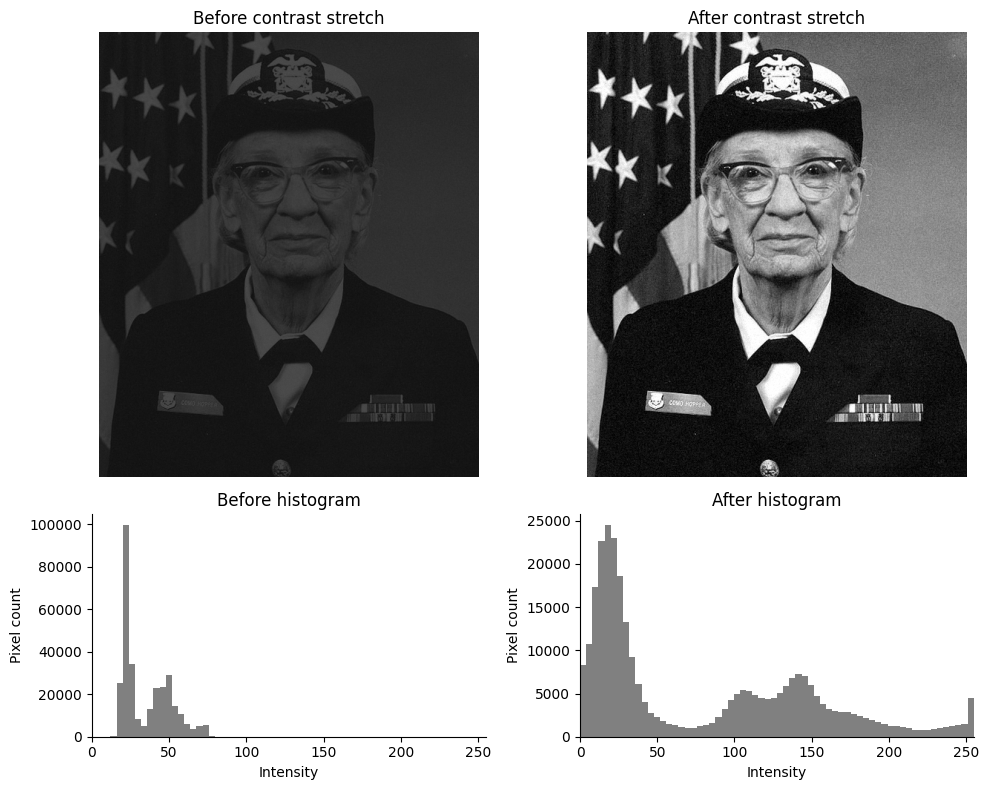

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) * (255.0 / (p99 - p1)), 0, 255)

s1, s99 = np.percentile(stretched, [1, 99])
c_after = michelson(s99, s1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Before contrast stretch")
axes[0, 0].axis("off")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray")
axes[1, 0].set(xlim=(0, 255), xlabel="Intensity", ylabel="Pixel count", title="Before histogram")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("After contrast stretch")
axes[0, 1].axis("off")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="gray")
axes[1, 1].set(xlim=(0, 255), xlabel="Intensity", ylabel="Pixel count", title="After histogram")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

The night image has a narrow histogram concentrated toward the lower intensity values, which indicates a dark, low-contrast image. Contrast stretching expands the intensity range, making differences between previously similar dark pixels more visible. However, it does not add new information because it only remaps existing pixel intensities; it cannot recover details that were never captured. A histogram also cannot identify the objects in an image because it describes the distribution of pixel intensities, not their spatial arrangement. Two completely different images can have the same histogram.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing ranges (s): 68.7-68.7, 68.8-68.8, 68.9-70.5, 70.6-70.8, 70.9-71.1, 71.2-71.6, 71.7-72.0, 72.1-72.1, 72.2-72.7, 72.8-73.2, 73.3-73.7, 73.8-73.9, 74.0-74.0, 74.1-74.2, 74.3-74.7, 74.7-75.4, 75.4-75.5, 75.5-75.6, 75.6-75.7, 75.7-75.7, 75.8-75.9, 76.0-76.5, 76.6-76.9, 77.0-78.1
Running ranges (s): 78.6-86.0


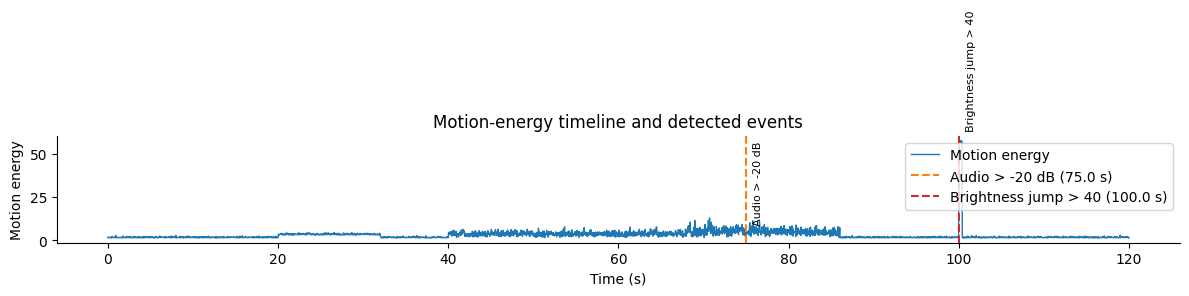

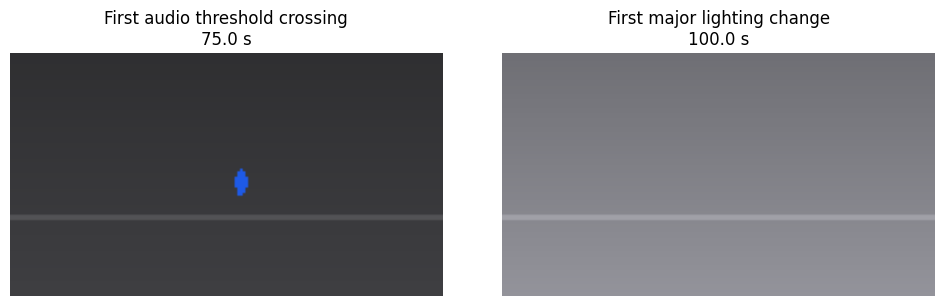

In [4]:
# TODO 1: person speed (px/s)
# Use a one-second displacement (FPS frames) to reduce single-frame tracking jitter.
xy = cctv[["person_x", "person_y"]].astype(float)
displacement = xy - xy.shift(FPS)
speed = np.sqrt(displacement["person_x"] ** 2 + displacement["person_y"] ** 2)

# TODO 2: standing / running time ranges (print the first and last time of each)
time_s = np.arange(len(cctv)) / FPS

def print_ranges(mask, label):
    mask = pd.Series(mask, index=np.arange(len(cctv))).fillna(False).astype(bool)
    groups = (mask != mask.shift(fill_value=False)).cumsum()
    ranges = []
    for _, idx in mask[mask].groupby(groups[mask]).groups.items():
        start_i, end_i = int(min(idx)), int(max(idx))
        ranges.append((time_s[start_i], time_s[end_i]))
    if ranges:
        print(f"{label} ranges (s): " + ", ".join(f"{a:.1f}-{b:.1f}" for a, b in ranges))
    else:
        print(f"No {label.lower()} ranges found.")

person_present = cctv["person_x"].notna() & cctv["person_y"].notna()
print_ranges(person_present & (speed < 3), "Standing")
print_ranges(person_present & (speed > 25), "Running")

# TODO 3: event frame indices
audio_crossings = np.flatnonzero(cctv["audio_level_db"].to_numpy() > -20)
audio_event_idx = int(audio_crossings[0]) if len(audio_crossings) else None
brightness_jump = cctv["mean_brightness"].diff().to_numpy()
lighting_crossings = np.flatnonzero(brightness_jump > 40)
lighting_event_idx = int(lighting_crossings[0]) if len(lighting_crossings) else None

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(time_s, cctv["motion_energy"], lw=1, label="Motion energy")
for idx, label, color in [(audio_event_idx, "Audio > -20 dB", "tab:orange"),
                           (lighting_event_idx, "Brightness jump > 40", "tab:red")]:
    if idx is not None:
        ax.axvline(time_s[idx], color=color, linestyle="--", label=f"{label} ({time_s[idx]:.1f} s)")
        ax.annotate(label, (time_s[idx], cctv["motion_energy"].iloc[idx]), xytext=(5, 8),
                    textcoords="offset points", rotation=90, va="bottom", fontsize=8)
ax.set(xlabel="Time (s)", ylabel="Motion energy", title="Motion-energy timeline and detected events")
ax.legend(loc="upper right")

plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
keyframes = [(audio_event_idx, "First audio threshold crossing"),
             (lighting_event_idx, "First major lighting change")]
keyframes = [(i, label) for i, label in keyframes if i is not None]
if keyframes:
    fig, axes = plt.subplots(1, len(keyframes), figsize=(5 * len(keyframes), 3))
    if len(keyframes) == 1:
        axes = [axes]
    for ax, (idx, label) in zip(axes, keyframes):
        ax.imshow(render_frame(cctv.iloc[idx]))
        ax.set_title(f"{label}\n{time_s[idx]:.1f} s")
        ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No audio or lighting events crossed the specified thresholds.")

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform keyframes taken every 20 seconds could miss brief events occurring between those sampling times, such as the sudden audio event around 75 seconds or a rapid change in lighting. A short event may begin and end between two selected frames. The content-based keyframe approach used here selects frames associated with detected events, making the summary more informative than uniform sampling. This is an example of event-driven or content-based keyframe selection.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

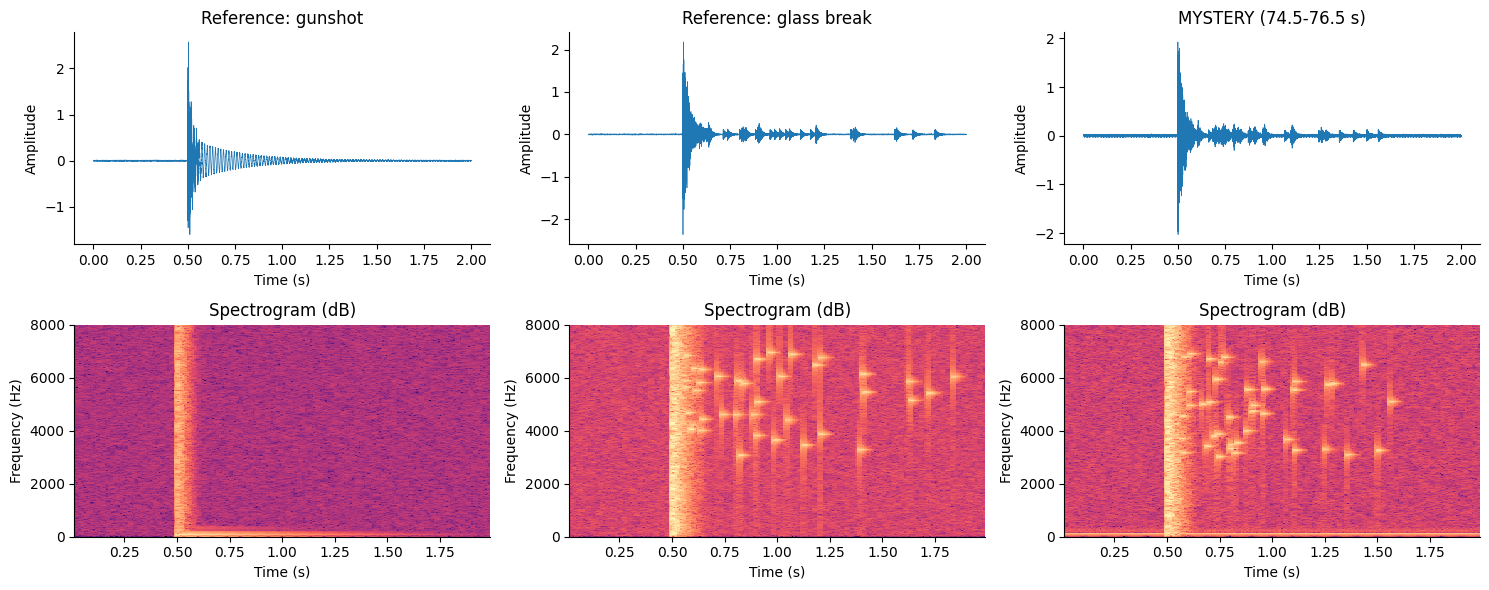

{'Reference: gunshot': 0.0030352610136762824, 'Reference: glass break': 0.9891874044148661, 'MYSTERY (74.5-76.5 s)': 0.8734552491106997}
Verdict: the mystery sound is more consistent with breaking glass based on high-frequency energy.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, clip) in enumerate(clips.items()):
    t_clip = np.arange(len(clip)) / FS
    axes[0, col].plot(t_clip, clip, lw=0.5)
    axes[0, col].set(title=name, xlabel="Time (s)", ylabel="Amplitude")
    f, tt, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + np.finfo(float).tiny)
    axes[1, col].pcolormesh(tt, f, Sxx_db, shading="auto", cmap="magma")
    axes[1, col].set(ylim=(0, 8000), xlabel="Time (s)", ylabel="Frequency (Hz)")
    axes[1, col].set_title("Spectrogram (dB)")

plt.tight_layout(); plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, clip in clips.items():
    f, tt, Sxx = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    window_mask = (tt >= 0.7) & (tt <= 1.7)  # 0.2-1.2 s after impact at 0.5 s
    high_mask = f > 3000
    total_energy = Sxx[:, window_mask].sum()
    hf_energy = Sxx[high_mask][:, window_mask].sum()
    hf_fraction[name] = float(hf_energy / total_energy) if total_energy > 0 else 0.0

print(hf_fraction)
# TODO 4: verdict
gunshot_score = hf_fraction["Reference: gunshot"]
glass_score = hf_fraction["Reference: glass break"]
mystery_score = hf_fraction["MYSTERY (74.5-76.5 s)"]
verdict = "breaking glass" if abs(mystery_score - glass_score) < abs(mystery_score - gunshot_score) else "gunshot"
print(f"Verdict: the mystery sound is more consistent with {verdict} based on high-frequency energy.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
No, waveforms alone would not allow me to confidently distinguish a gunshot from breaking glass because both can produce a sudden, high-amplitude transient. A spectrogram adds three dimensions: time, frequency and signal magnitude or energy, represented by colour intensity. A gunshot may produce a sharp vertical stripe associated with a broadband transient, while breaking glass may produce scattered high-frequency specks that continue as the fragments resonate and fall. I would compare the mystery recording's pattern and high-frequency energy with both reference recordings before deciding which event it more closely resembles.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

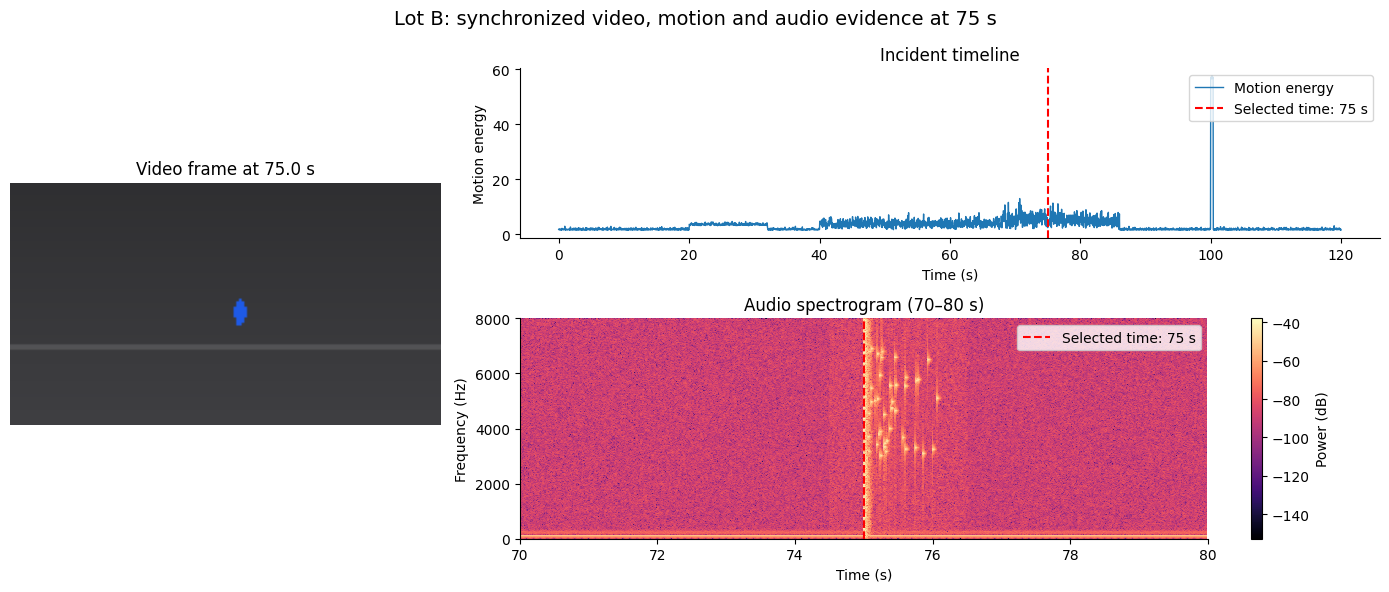

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
frame_idx = int(np.clip(round(t_sel * FPS), 0, len(cctv) - 1))
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.set_title(f"Video frame at {time_s[frame_idx]:.1f} s")
ax_frame.axis("off")

ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(time_s, cctv["motion_energy"], label="Motion energy", lw=1)
ax_timeline.set(xlabel="Time (s)", ylabel="Motion energy", title="Incident timeline")
ax_timeline.axvline(t_sel, color="red", linestyle="--", label="Selected time: 75 s")
ax_timeline.legend(loc="upper right")

ax_spec = fig.add_subplot(gs[1, 1])
audio_times = t_audio
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
Sxx_db = 10 * np.log10(Sxx + np.finfo(float).tiny)
absolute_tt = audio_times[0] + tt
mesh = ax_spec.pcolormesh(absolute_tt, f, Sxx_db, shading="auto", cmap="magma")
ax_spec.set(xlim=(70, 80), ylim=(0, 8000), xlabel="Time (s)", ylabel="Frequency (Hz)", title="Audio spectrogram (70–80 s)")
ax_spec.axvline(t_sel, color="red", linestyle="--", label="Selected time: 75 s")
ax_spec.legend(loc="upper right")
fig.colorbar(mesh, ax=ax_spec, label="Power (dB)")
fig.suptitle("Lot B: synchronized video, motion and audio evidence at 75 s", fontsize=14)

plt.tight_layout(); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_
If the audio track were offset by +2 seconds, a sound could appear to occur two seconds later than the corresponding visual event. This could lead the security team to associate the sound with the wrong action or person and draw an incorrect conclusion about what happened. The synchronized briefing panel would reveal the problem if its audio event marker did not align with the corresponding video or motion event. Correct synchronization is essential when combining modalities, and the display should use a shared time reference. The timeline and spectrogram should therefore be checked together before making a final decision.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

The Parking Lot B recording shows detected motion and changes in the audio and lighting; the sound around 75 seconds should be classified as **[insert the verdict printed by the notebook: gunshot or breaking glass]**, with the associated events confirmed using their detected timestamps. I recommend presenting the synchronized multimodal view first because it connects the video frame, motion timeline and audio spectrogram using a common time reference. This follows the principle of moving from structure and patterns to changes, events and their meaning, while allowing the team to cross-check evidence from different modalities. For storage, I recommend retaining the original high-quality recording for important incidents and using lower-resolution, lower-frame-rate copies for routine monitoring or previews. The storage policy must not sacrifice critical spatial details or brief temporal events that could be necessary for identifying people, objects or actions during an investigation.